In [1]:
# 定位仓库根目录，让当前内核能导入 src 下的模块。
import sys
from pathlib import Path

working_dir: Path = Path.cwd().resolve()
repo_root: Path = (
    working_dir.parent if working_dir.name == "notebook" else working_dir
)
if not (repo_root / "config" / "offline.json").is_file():
    raise FileNotFoundError(f"找不到项目配置，请从仓库或 notebook/ 目录运行：{working_dir}")

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
print(sys.executable)

SVP_env/bin/python


In [2]:
# 读取离线实验配置。
from src.config import OfflineConfig, load_offline_config

settings: OfflineConfig = load_offline_config(repo_root / "config" / "offline.json")
print(f"{settings.split}/{settings.scene_name}")

trainingQ/Adirondack


In [3]:
# 读取左右图、标定及训练集视差真值。
from src.datasets import MiddleburyScene, load_middlebury_scene

scene: MiddleburyScene = load_middlebury_scene(
    settings.image_root,
    settings.split,
    settings.scene_name,
    ground_truth_root=settings.ground_truth_root,
)
print(f"左图形状：{scene.rectified_pair.left_bgr.shape}")
print(f"有左视差真值：{scene.ground_truth is not None}")

左图形状：(496, 718, 3)
有左视差真值：True


搜索 ROI：(129, 2, 587, 492)
全图有效匹配率：77.76%
搜索 ROI 有效匹配率：95.89%
非遮挡真值覆盖率：82.13%
有效交集视差 MAE：1.304 px
有效交集视差 RMSE：5.280 px


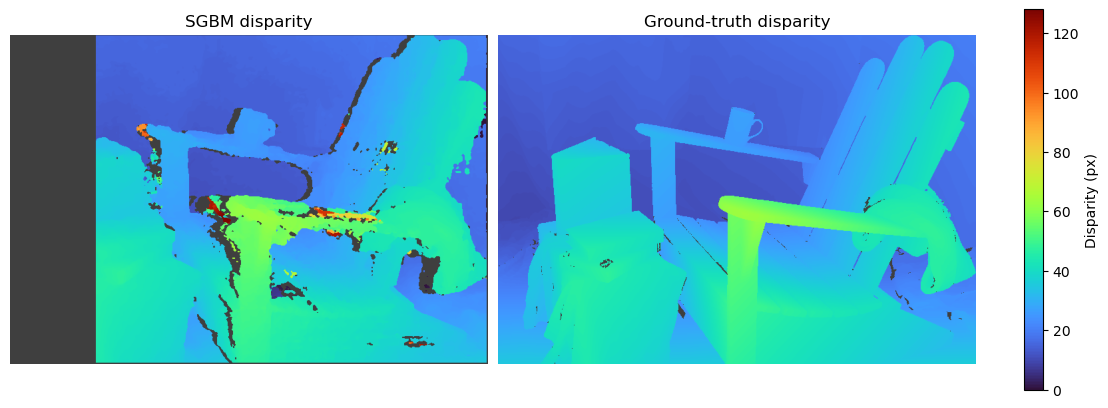

In [4]:
# 调用项目模块计算视差，再检查数值和匹配有效性。
import matplotlib.pyplot as plt
import numpy as np

from src.datasets import MiddleburyGroundTruth
from src.disparity import compute_disparity
from src.evaluation import DisparityMetrics, evaluate_disparity
from src.model import DisparityResult

result: DisparityResult = compute_disparity(
    scene.rectified_pair, scene.geometry, settings.sgbm
)
width: int
height: int
width, height = scene.geometry.image_size
assert result.disparity_px.shape == result.valid_mask.shape == (height, width)
assert result.disparity_px.dtype == np.float32 and result.valid_mask.dtype == np.bool_
assert np.array_equal(np.isfinite(result.disparity_px), result.valid_mask)

print(f"搜索 ROI：{result.valid_roi}")
truth: MiddleburyGroundTruth | None = scene.ground_truth
metrics: DisparityMetrics = evaluate_disparity(
    result,
    reference_px=truth.disparity_px if truth is not None else None,
    reference_mask=truth.non_occluded_mask if truth is not None else None,
)
print(f"全图有效匹配率：{metrics.image_match_rate:.2%}")
print(f"搜索 ROI 有效匹配率：{metrics.search_roi_match_rate:.2%}")
if metrics.reference_coverage is not None:
    print(f"非遮挡真值覆盖率：{metrics.reference_coverage:.2%}")
if metrics.mae_px is not None and metrics.rmse_px is not None:
    print(f"有效交集视差 MAE：{metrics.mae_px:.3f} px")
    print(f"有效交集视差 RMSE：{metrics.rmse_px:.3f} px")
else:
    print("视差误差未评估：没有共同有效的参考像素")

# 预测和真值共用搜索范围对应的色标，灰色表示无效像素。
vmin: int = settings.sgbm.min_disparity
vmax: int = vmin + settings.sgbm.num_disparities
cmap = plt.get_cmap("turbo").with_extremes(bad="0.25")
if truth is None:
    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    axes = [ax]
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    axes[1].imshow(np.ma.masked_invalid(truth.disparity_px), cmap=cmap, vmin=vmin, vmax=vmax)
    axes[1].set_title("Ground-truth disparity")
image = axes[0].imshow(result.disparity_px, cmap=cmap, vmin=vmin, vmax=vmax)
axes[0].set_title("SGBM disparity")
for ax in axes:
    ax.set_axis_off()
fig.colorbar(image, ax=list(axes), label="Disparity (px)")
plt.show()

有效三维点：276,937
轴向深度中位数：2.121 m


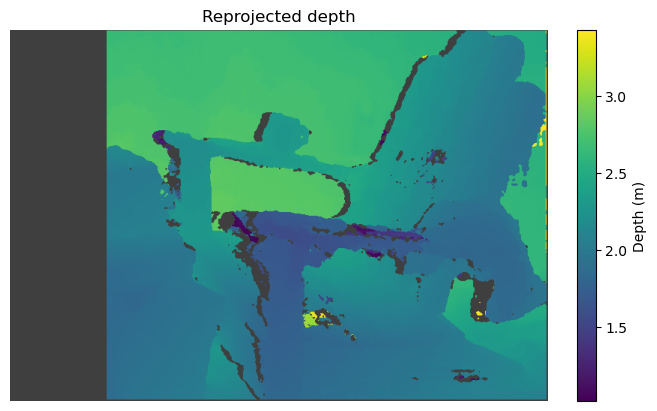

In [5]:
# 重投影视差，并检查深度、三维坐标及无效值。
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.image import AxesImage

from src.model import ReconstructionResult, ValidMask
from src.reprojection import reproject_disparity

reconstruction: ReconstructionResult = reproject_disparity(
    scene.rectified_pair, scene.geometry, result
)
valid: ValidMask = reconstruction.valid_mask
assert reconstruction.depth_m.shape == result.disparity_px.shape
assert reconstruction.xyz_m.shape == (*valid.shape, 3)
assert reconstruction.depth_m.dtype == reconstruction.xyz_m.dtype == np.float32
assert np.array_equal(np.isfinite(reconstruction.xyz_m).all(axis=2), valid)
assert np.array_equal(reconstruction.xyz_m[..., 2], reconstruction.depth_m, equal_nan=True)
assert np.all(reconstruction.depth_m[valid] > 0)
assert np.isnan(reconstruction.xyz_m[~valid]).all()

point_count: int = int(np.count_nonzero(valid))
median_depth_m: float = float(np.median(reconstruction.depth_m[valid]))
print(f"有效三维点：{point_count:,}")
print(f"轴向深度中位数：{median_depth_m:.3f} m")

fig: Figure
ax: Axes
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
depth_image: AxesImage = ax.imshow(
    reconstruction.depth_m, cmap=plt.get_cmap("viridis").with_extremes(bad="0.25")
)
ax.set_title("Reprojected depth")
ax.set_axis_off()
fig.colorbar(depth_image, ax=ax, label="Depth (m)")
plt.show()

In [6]:
# 导出本次离线重建和评估结果。
from dataclasses import asdict

from src.outputs import export_offline_result

if settings.output_root is None:
    print("未配置 output_root，跳过文件导出。")
else:
    run_dir: Path = export_offline_result(
        settings.output_root,
        reconstruction,
        asdict(metrics),
        split=settings.split,
        scene_name=settings.scene_name,
        sgbm=settings.sgbm,
        search_roi=result.valid_roi,
    )
    print(f"导出目录：{run_dir}")

导出目录：outputs/trainingQ/Adirondack/run-28375719ec7846be8aa48d61f51ffc5e
